   # Stellar Photometric Variability: Gaia DR3 pilot
   Query date 2026-10-12, Gaia DR3. Purpose: check data pulls and distributions.

In [1]:
from astroquery.gaia import Gaia
import pandas as pd
from datetime import date

query = """
SELECT TOP 2000
    v.source_id, v.best_class_name, v.best_class_score,
    g.phot_g_mean_mag, g.bp_rp, g.parallax, g.parallax_over_error
FROM gaiadr3.vari_classifier_result AS v
JOIN gaiadr3.gaia_source AS g USING (source_id)
"""

job = Gaia.launch_job(query)
df = job.get_results().to_pandas()

print("Query date:", date.today(), "| Release: Gaia DR3")
print(df.shape)

In preparation for Gaia DR4, the Gaia archive is in evolution. Unfortunately, it may be unstable at times and particular types of queries may time out. Please consider registering for a user account (https://www.cosmos.esa.int/web/gaia-users/register). For questions or advice, please contact the Gaia helpdesk (https://www.cosmos.esa.int/web/gaia/gaia-helpdesk).
Query date: 2026-10-13 | Release: Gaia DR3
(2000, 7)


In [2]:
df.to_csv("../data/raw/gaia_dr3_pilot2000_raw.csv", index=False)

In [3]:
df.head(10)

,source_id,best_class_name,best_class_score,phot_g_mean_mag,bp_rp,parallax,parallax_over_error
0,137356799338867200,ECL,0.056985,17.894846,1.039455,0.331376,2.625999
1,138766205742076160,SOLAR_LIKE,0.658701,12.817227,1.142434,4.321960,203.769241
2,138835573758118400,ECL,0.150160,18.406195,1.053791,-0.321751,-1.274034
3,138855914723795200,ECL,0.055173,18.627502,1.348022,0.282315,1.129909
4,138923676423051520,RS,0.358712,17.231886,1.743946,0.940185,10.010887
5,138976281182394496,RS,0.337457,16.254026,1.749743,1.623071,27.357477
6,138997373766199808,AGN,0.695668,19.790007,0.770061,-0.432825,-0.962915
7,139015897960755456,AGN,0.289092,19.891090,0.601709,0.359405,0.631644
8,139152924597713024,RS,0.058580,16.371868,1.616883,1.213642,20.441204
9,139188693085325184,SOLAR_LIKE,0.461840,15.420977,1.287720,1.527437,32.904564


## 2. Class counts and missing values

In [4]:
print(df["best_class_name"].value_counts())
print()
print(df.isna().mean().round(3))

best_class_name
ECL                           486
AGN                           448
DSCT|GDOR|SXPHE               333
SOLAR_LIKE                    285
RS                            273
S                              78
LPV                            67
RR                             13
ACV|CP|MCP|ROAM|ROAP|SXARI      5
CV                              4
YSO                             4
BCEP                            1
SN                              1
CEP                             1
WD                              1
Name: count, dtype: int64

source_id              0.000
best_class_name        0.000
best_class_score       0.000
phot_g_mean_mag        0.000
bp_rp                  0.003
parallax               0.051
parallax_over_error    0.051
dtype: float64


## 3. Removing AGN (not stars)

In [5]:
stars = df[df["best_class_name"] != "AGN"].copy()
print(len(stars))
print(stars["best_class_name"].value_counts().head(8))
print(stars["best_class_score"].describe().round(2))

1552
best_class_name
ECL                           486
DSCT|GDOR|SXPHE               333
SOLAR_LIKE                    285
RS                            273
S                              78
LPV                            67
RR                             13
ACV|CP|MCP|ROAM|ROAP|SXARI      5
Name: count, dtype: int64
count    1552.00
mean        0.47
std         0.28
min         0.00
25%         0.24
50%         0.44
75%         0.70
max         1.00
Name: best_class_score, dtype: float64


## 4. Finding the amplitude table

In [6]:
tables = Gaia.load_tables(only_names=True)
vari = [t.name for t in tables if "vari" in t.name]
for name in vari:
    print(name)

INFO: Retrieving tables... [astroquery.utils.tap.core]
INFO: Parsing tables... [astroquery.utils.tap.core]
INFO: Done. [astroquery.utils.tap.core]
gaiadr1.phot_variable_time_series_gfov
gaiadr1.phot_variable_time_series_gfov_statistical_parameters
gaiadr1.variable_summary
gaiadr2.vari_cepheid
gaiadr2.vari_classifier_class_definition
gaiadr2.vari_classifier_definition
gaiadr2.vari_classifier_result
gaiadr2.vari_long_period_variable
gaiadr2.vari_rotation_modulation
gaiadr2.vari_rrlyrae
gaiadr2.vari_short_timescale
gaiadr2.vari_time_series_statistics
gaiadr3.vari_spurious_signals
gaiadr3.vari_agn
gaiadr3.vari_cepheid
gaiadr3.vari_classifier_class_definition
gaiadr3.vari_classifier_definition
gaiadr3.vari_classifier_result
gaiadr3.vari_compact_companion
gaiadr3.vari_eclipsing_binary
gaiadr3.vari_epoch_radial_velocity
gaiadr3.vari_long_period_variable
gaiadr3.vari_microlensing
gaiadr3.vari_ms_oscillator
gaiadr3.vari_planetary_transit
gaiadr3.vari_planetary_transit_13june2022
gaiadr3.vari_ra

In [7]:
t = Gaia.load_table("gaiadr3.vari_summary")
for col in t.columns:
    if "g_fov" in col.name:
        print(col.name)

num_selected_g_fov
mean_obs_time_g_fov
time_duration_g_fov
min_mag_g_fov
max_mag_g_fov
mean_mag_g_fov
median_mag_g_fov
range_mag_g_fov
trimmed_range_mag_g_fov
std_dev_mag_g_fov
skewness_mag_g_fov
kurtosis_mag_g_fov
mad_mag_g_fov
abbe_mag_g_fov
iqr_mag_g_fov
stetson_mag_g_fov
std_dev_over_rms_err_mag_g_fov
outlier_median_g_fov


## 5. Amplitude from vari_summary (G band)

In [8]:
query = """
SELECT TOP 2000
    v.source_id, v.best_class_name, v.best_class_score,
    g.phot_g_mean_mag, g.bp_rp, g.parallax, g.parallax_over_error,
    s.num_selected_g_fov, s.mean_mag_g_fov, s.range_mag_g_fov,
    s.trimmed_range_mag_g_fov, s.std_dev_mag_g_fov
FROM gaiadr3.vari_classifier_result AS v
JOIN gaiadr3.gaia_source AS g USING (source_id)
JOIN gaiadr3.vari_summary AS s USING (source_id)
WHERE v.best_class_name <> 'AGN'
"""

job = Gaia.launch_job(query)
df2 = job.get_results().to_pandas()

print("Query date:", date.today(), "| Release: Gaia DR3")
print(df2.shape)
print(df2["best_class_name"].value_counts().head(8))
print(df2.isna().mean().round(3))
df2.to_csv("../data/raw/gaia_dr3_pilot_amplitude_raw.csv", index=False)
df2.head()

Query date: 2026-10-13 | Release: Gaia DR3
(2000, 12)
best_class_name
SOLAR_LIKE         625
ECL                524
DSCT|GDOR|SXPHE    329
RS                 248
S                  181
LPV                 63
RR                  11
YSO                  6
Name: count, dtype: int64
source_id                  0.000
best_class_name            0.000
best_class_score           0.000
phot_g_mean_mag            0.000
bp_rp                      0.003
parallax                   0.096
parallax_over_error        0.096
num_selected_g_fov         0.000
mean_mag_g_fov             0.000
range_mag_g_fov            0.000
trimmed_range_mag_g_fov    0.000
std_dev_mag_g_fov          0.000
dtype: float64


,source_id,best_class_name,best_class_score,phot_g_mean_mag,bp_rp,parallax,parallax_over_error,num_selected_g_fov,mean_mag_g_fov,range_mag_g_fov,trimmed_range_mag_g_fov,std_dev_mag_g_fov
0,138764968791499392,DSCT|GDOR|SXPHE,0.260598,12.372994,0.435971,1.003164,23.413029,23,12.373236,0.016651,0.014880,0.005039
1,138901716253814272,ECL,0.175072,15.874887,NaN,0.681523,10.424718,27,15.875300,0.164173,0.150826,0.045361
2,139138012471328512,RS,0.000604,17.182072,1.625938,1.126886,9.534678,24,17.181948,0.075942,0.068791,0.020699
3,139290363551696256,SOLAR_LIKE,0.041168,15.479699,1.185102,1.070740,29.567904,31,15.479853,0.025623,0.024794,0.006789
4,139518512214669184,RS,0.225077,14.551616,1.306562,0.478560,16.243399,26,14.550899,0.049534,0.035894,0.012876


## 6. Finding period columns

In [9]:
tables_to_check = [
    "gaiadr3.vari_eclipsing_binary",
    "gaiadr3.vari_rrlyrae",
    "gaiadr3.vari_cepheid",
    "gaiadr3.vari_long_period_variable",
    "gaiadr3.vari_rotation_modulation",
    "gaiadr3.vari_short_timescale",
]

for name in tables_to_check:
    try:
        t = Gaia.load_table(name)
        cols = [c.name for c in t.columns
                if "period" in c.name or "frequency" in c.name or "amplitude" in c.name]
        print(name)
        print("   ", cols)
    except Exception as e:
        print(name, "-> failed:", str(e)[:80])

gaiadr3.vari_eclipsing_binary
    ['frequency', 'frequency_error', 'geom_model_cosine_half_period_amplitude', 'geom_model_cosine_half_period_amplitude_error', 'geom_model_cosine_half_period_phase', 'geom_model_cosine_half_period_phase_error']
gaiadr3.vari_rrlyrae
    []
gaiadr3.vari_cepheid
    []
gaiadr3.vari_long_period_variable
    ['frequency', 'frequency_error', 'amplitude']
gaiadr3.vari_rotation_modulation
    ['segments_rotation_period', 'segments_rotation_period_error', 'segments_rotation_period_fap', 'best_rotation_period', 'best_rotation_period_error']
gaiadr3.vari_short_timescale
    ['amplitude_estimate', 'frequency']


In [10]:
for name in ["gaiadr3.vari_rrlyrae", "gaiadr3.vari_cepheid"]:
    t = Gaia.load_table(name)
    print(name)
    print([c.name for c in t.columns])
    print()

gaiadr3.vari_rrlyrae
['solution_id', 'source_id', 'pf', 'pf_error', 'p1_o', 'p1_o_error', 'epoch_g', 'epoch_g_error', 'epoch_bp', 'epoch_bp_error', 'epoch_rp', 'epoch_rp_error', 'epoch_rv', 'epoch_rv_error', 'int_average_g', 'int_average_g_error', 'int_average_bp', 'int_average_bp_error', 'int_average_rp', 'int_average_rp_error', 'average_rv', 'average_rv_error', 'peak_to_peak_g', 'peak_to_peak_g_error', 'peak_to_peak_bp', 'peak_to_peak_bp_error', 'peak_to_peak_rp', 'peak_to_peak_rp_error', 'peak_to_peak_rv', 'peak_to_peak_rv_error', 'metallicity', 'metallicity_error', 'r21_g', 'r21_g_error', 'r31_g', 'r31_g_error', 'phi21_g', 'phi21_g_error', 'phi31_g', 'phi31_g_error', 'num_clean_epochs_g', 'num_clean_epochs_bp', 'num_clean_epochs_rp', 'num_clean_epochs_rv', 'zp_mag_g', 'zp_mag_bp', 'zp_mag_rp', 'num_harmonics_for_p1_g', 'num_harmonics_for_p1_bp', 'num_harmonics_for_p1_rp', 'num_harmonics_for_p1_rv', 'reference_time_g', 'reference_time_bp', 'reference_time_rp', 'reference_time_rv', '

## 7. RR Lyrae and Cepheid pull

In [11]:
q_rr = """
SELECT TOP 2000
    r.source_id, r.pf, r.p1_o, r.peak_to_peak_g, r.int_average_g,
    r.num_clean_epochs_g, r.best_classification,
    g.bp_rp, g.parallax, g.parallax_over_error
FROM gaiadr3.vari_rrlyrae AS r
JOIN gaiadr3.gaia_source AS g USING (source_id)
"""

q_cep = """
SELECT TOP 2000
    c.source_id, c.pf, c.p1_o, c.peak_to_peak_g, c.int_average_g,
    c.num_clean_epochs_g, c.type_best_classification, c.mode_best_classification,
    g.bp_rp, g.parallax, g.parallax_over_error
FROM gaiadr3.vari_cepheid AS c
JOIN gaiadr3.gaia_source AS g USING (source_id)
"""

rr = Gaia.launch_job(q_rr).get_results().to_pandas()
cep = Gaia.launch_job(q_cep).get_results().to_pandas()

print("Query date:", date.today(), "| Release: Gaia DR3")
print("RR Lyrae:", rr.shape, "| Cepheids:", cep.shape)

rr.to_csv("../data/raw/gaia_dr3_rrlyrae_pilot_raw.csv", index=False)
cep.to_csv("../data/raw/gaia_dr3_cepheid_pilot_raw.csv", index=False)

print(rr.isna().mean().round(3))
print(cep.isna().mean().round(3))

Query date: 2026-10-13 | Release: Gaia DR3
RR Lyrae: (2000, 10) | Cepheids: (2000, 11)
source_id              0.000
pf                     0.369
p1_o                   0.626
peak_to_peak_g         0.000
int_average_g          0.000
num_clean_epochs_g     0.000
best_classification    0.000
bp_rp                  0.081
parallax               0.026
parallax_over_error    0.026
dtype: float64
source_id                   0.000
pf                          0.404
p1_o                        0.597
peak_to_peak_g              0.000
int_average_g               0.000
num_clean_epochs_g          0.000
type_best_classification    0.000
mode_best_classification    0.000
bp_rp                       0.000
parallax                    0.000
parallax_over_error         0.000
dtype: float64


## 8. Combined period column

In [12]:
import numpy as np
import matplotlib.pyplot as plt

for d in (rr, cep):
    d["period"] = d["pf"].fillna(d["p1_o"])
    d["period_type"] = np.where(d["pf"].notna(), "fundamental", "overtone")

print(rr["period"].isna().sum(), cep["period"].isna().sum(), "stars with no period")
print(rr["period_type"].value_counts())
print(cep["period_type"].value_counts())

0 9 stars with no period
period_type
fundamental    1262
overtone        738
Name: count, dtype: int64
period_type
fundamental    1193
overtone        807
Name: count, dtype: int64


## 9. First scatter plots

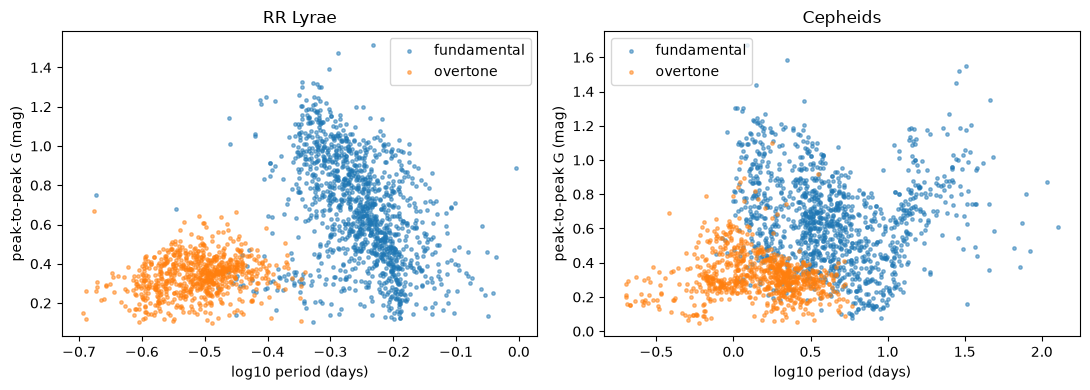

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, d, title in [(ax[0], rr, "RR Lyrae"), (ax[1], cep, "Cepheids")]:
    d2 = d.dropna(subset=["period"])
    for k, grp in d2.groupby("period_type"):
        a.scatter(np.log10(grp["period"]), grp["peak_to_peak_g"], s=6, alpha=0.5, label=k)
    a.set_xlabel("log10 period (days)")
    a.set_ylabel("peak-to-peak G (mag)")
    a.set_title(title)
    a.legend()
plt.tight_layout()
plt.show()